# MLP com ModelNet10: otimização de hiperparâmetros

**Integrantes:** _preencher_

**Declaração de uso de IA:** _preencher_

Notebook construído por etapas, seguindo `doc/step-by-step/README.md`.

## Etapa 0: Ambiente e configuração

### 0.1 Versões

Versões usadas neste notebook (Python 3.11.9, registrado também em `.python-version`).

In [1]:
import sys, numpy, pandas, sklearn, optuna, h5py

# Registra as versões para garantir reprodutibilidade
print('Python', sys.version.split()[0])
for m in (numpy, pandas, sklearn, optuna, h5py):
    print(m.__name__, m.__version__)

Python 3.11.9
numpy 2.4.6
pandas 3.0.5
sklearn 1.9.1
optuna 5.0.0
h5py 3.16.0


### 0.2 Constantes e caminhos

Seed fixa para reprodutibilidade e caminhos dos arquivos.

In [2]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

# Seed única, reutilizada em folds, buscas e modelos
SEED = 42

# Arquivos oficiais do ModelNet10, com caminho relativo à pasta notebooks/
DATA_DIR = Path('../dataset/modelnet10_hdf5')
TRAIN_FILE = DATA_DIR / 'modelnet10_train_0.h5'
TEST_FILE = DATA_DIR / 'modelnet10_test_0.h5'

# O arquivo traz só ids de 0 a 9; os nomes seguem a ordem alfabética padrão do ModelNet10
CLASS_NAMES = ['Banheira', 'Cama', 'Cadeira', 'Mesa de escritório', 'Cômoda',
               'Monitor', 'Mesa de cabeceira', 'Sofá', 'Mesa', 'Vaso sanitário']

## Etapa 2: Carregar e conferir os dados

Cada objeto é uma **nuvem de 2.048 pontos** (X, Y, Z) com um rótulo de 0 a 9. Aqui só *inspecionamos* os dados; o teste não é usado para nenhuma decisão.

### 2.1 Carregamento

In [3]:
def load_h5(path):
    """Lê um arquivo HDF5 e devolve (nuvens, rótulos)."""
    with h5py.File(path, 'r') as f:
        # data: (n_objetos, 2048, 3) | label: (n_objetos,)
        return f['data'][:], f['label'][:].ravel()


X_train_pts, y_train = load_h5(TRAIN_FILE)
X_test_pts, y_test = load_h5(TEST_FILE)

# Esperado: treino (3991, 2048, 3) e teste (908, 2048, 3)
print('treino:', X_train_pts.shape, y_train.shape, X_train_pts.dtype)
print('teste :', X_test_pts.shape, y_test.shape, X_test_pts.dtype)

treino: (3991, 2048, 3) (3991,) float32
teste : (908, 2048, 3) (908,) float32


### 2.2 Distribuição por classe

O arquivo traz só ids numéricos (0–9), sem nomes. Classes desbalanceadas justificam usar **validação estratificada** e **F1 macro**.

,treino,teste,treino_%,teste_%
0: Banheira,106,50,2.7,5.5
1: Cama,515,100,12.9,11.0
2: Cadeira,889,100,22.3,11.0
3: Mesa de escritório,200,86,5.0,9.5
4: Cômoda,200,86,5.0,9.5
5: Monitor,465,100,11.7,11.0
6: Mesa de cabeceira,200,86,5.0,9.5
7: Sofá,680,100,17.0,11.0
8: Mesa,392,100,9.8,11.0
9: Vaso sanitário,344,100,8.6,11.0


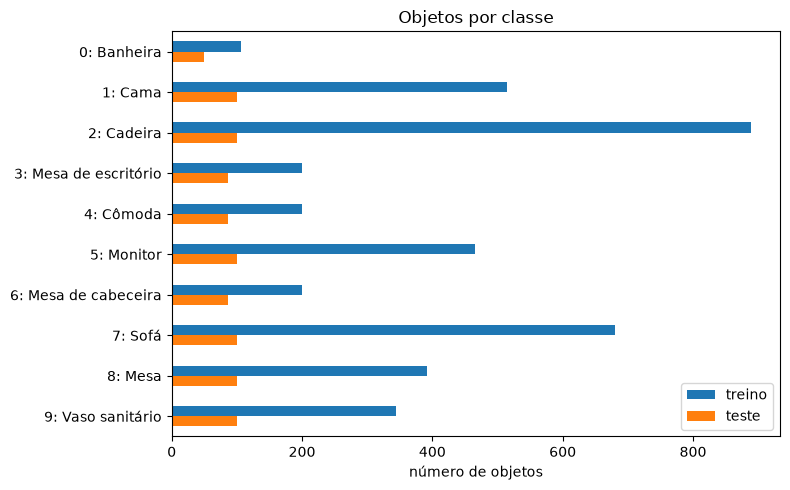

In [4]:
# Contagem de objetos por classe em treino e teste
dist = pd.DataFrame({
    'treino': pd.Series(y_train).value_counts().sort_index(),
    'teste': pd.Series(y_test).value_counts().sort_index(),
})
dist.index = [f'{i}: {n}' for i, n in enumerate(CLASS_NAMES)]

# Percentual de cada classe dentro do próprio conjunto
dist['treino_%'] = (100 * dist['treino'] / dist['treino'].sum()).round(1)
dist['teste_%'] = (100 * dist['teste'] / dist['teste'].sum()).round(1)
display(dist)

# Barras horizontais, pois os nomes das classes são longos para o eixo X
ax = dist[['treino', 'teste']].plot.barh(figsize=(8, 5), title='Objetos por classe')

# Classe 0 no topo e legenda na região vazia, sem cobrir as barras
ax.invert_yaxis()
ax.legend(loc='lower right')
ax.set_xlabel('número de objetos'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

### 2.3 Valores ausentes, inválidos e faixa das coordenadas

In [5]:
for nome, pts, y in [('treino', X_train_pts, y_train), ('teste', X_test_pts, y_test)]:
    print(f'--- {nome} ---')

    # Valores ausentes ou inválidos nas coordenadas
    print('NaN:', int(np.isnan(pts).sum()), '| inf:', int(np.isinf(pts).sum()))
    print('rótulos únicos:', np.unique(y))

    # Faixa global de X, Y e Z (reshape junta os pontos de todos os objetos)
    print('min por eixo:', pts.reshape(-1, 3).min(0).round(3))
    print('max por eixo:', pts.reshape(-1, 3).max(0).round(3))

    # Tamanho do objeto: maior extensão entre os 3 eixos (varia entre objetos)
    extent = (pts.max(1) - pts.min(1)).max(1)
    print('maior extensão por objeto: min %.3f | mediana %.3f | max %.3f'
          % (extent.min(), np.median(extent), extent.max()))

    # Centróide médio perto de 0 indica objetos já centrados
    print('centróide médio:', pts.mean(1).mean(0).round(3))

--- treino ---
NaN: 0 | inf: 0
rótulos únicos: [0 1 2 3 4 5 6 7 8 9]


min por eixo: [-0.996 -0.992 -1.   ]


max por eixo: [0.991 0.994 1.   ]


maior extensão por objeto: min 0.936 | mediana 1.525 | max 1.997
centróide médio: [ 0. -0.  0.]
--- teste ---
NaN: 0 | inf: 0
rótulos únicos: [0 1 2 3 4 5 6 7 8 9]
min por eixo: [-0.973 -0.949 -0.997]
max por eixo: [0.987 0.996 0.99 ]


maior extensão por objeto: min 0.926 | mediana 1.489 | max 1.980
centróide médio: [-0. -0. -0.]


### 2.4 Um exemplo de cada classe

O primeiro objeto de treino de cada classe, colorido pela altura (eixo Z).

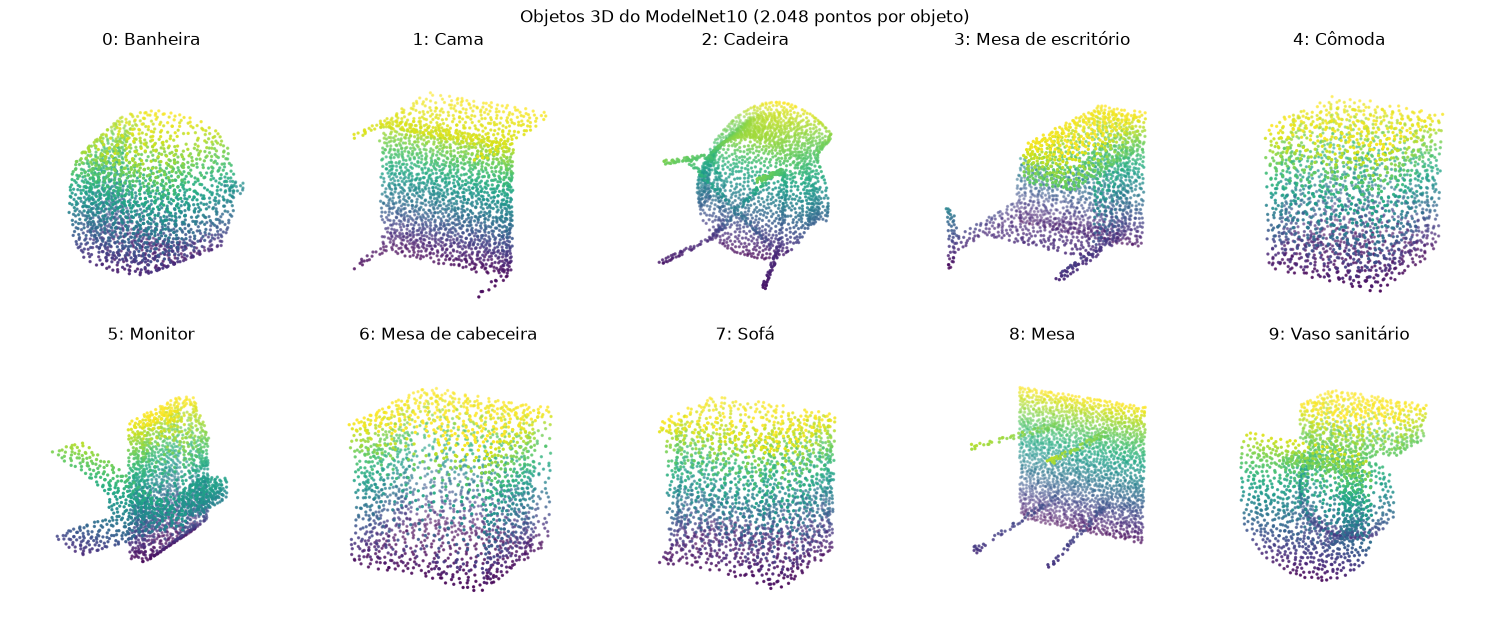

In [6]:
fig = plt.figure(figsize=(15, 6.5))
for c in range(10):
    # Primeiro objeto de treino da classe c, com shape (2048, 3)
    p = X_train_pts[np.where(y_train == c)[0][0]]

    ax = fig.add_subplot(2, 5, c + 1, projection='3d')

    # Cor pela altura (Z); a viridis não tem extremo claro e aparece bem no fundo branco
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap='viridis', s=2)

    # Ângulo de visão e eixos com a mesma escala
    ax.view_init(elev=20, azim=-60)
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(f'{c}: {CLASS_NAMES[c]}'); ax.set_axis_off()

fig.suptitle('Objetos 3D do ModelNet10 (2.048 pontos por objeto)')
plt.tight_layout(); plt.show()

## Etapa 3: Preparar a entrada da MLP

Uma MLP precisa de um vetor de tamanho fixo e com ordem, e uma nuvem de pontos não tem ordem. Por isso dividimos o espaço em **8×8×8 = 512 células** (voxels): cada célula vale **1** se contém algum ponto e **0** caso contrário.

**Transformação (determinística, por objeto):**
1. Centralizar o objeto no centro da sua caixa delimitadora.
2. Dividir pela maior extensão entre os eixos, o que coloca o objeto em [0, 1]³ sem deformar a proporção.
3. Multiplicar por 8 e truncar para obter o índice (0 a 7) da célula de cada ponto.

Cada objeto usa só os próprios pontos, então nada é ajustado com o conjunto de teste e a mesma função vale para treino e teste.

### 3.1 Transformação

In [7]:
# Células por eixo, o que dá 8*8*8 = 512 atributos
GRID = 8


def voxelize(points, grid=GRID):
    """Converte uma nuvem (n_pontos, 3) em um vetor binário de grid**3 posições."""
    mins, maxs = points.min(0), points.max(0)
    center = (mins + maxs) / 2
    extent = (maxs - mins).max()

    # Objeto centrado e escalado para o cubo [0, 1]^3, mantendo a proporção
    unit = (points - center) / extent + 0.5

    # Índice da célula em cada eixo; o clip evita o índice 8 para pontos em 1.0
    idx = np.clip((unit * grid).astype(int), 0, grid - 1)

    # Marca como ocupadas as células que contêm algum ponto
    vox = np.zeros((grid, grid, grid), dtype=np.uint8)
    vox[idx[:, 0], idx[:, 1], idx[:, 2]] = 1
    return vox.ravel()


def voxelize_all(clouds):
    """Aplica voxelize a cada objeto e empilha em (n_objetos, grid**3)."""
    return np.stack([voxelize(p) for p in clouds])


# Mesma função, aplicada igualmente a treino e teste
X_train = voxelize_all(X_train_pts)
X_test = voxelize_all(X_test_pts)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (3991, 512) | X_test: (908, 512)


### 3.2 Conferência da transformação

In [8]:
for nome, X in [('treino', X_train), ('teste', X_test)]:
    # Células ocupadas por objeto
    occupied = X.sum(1)
    print(f'--- {nome} ---')
    print('valores:', np.unique(X))
    print('células ocupadas por objeto: min %d | mediana %d | max %d'
          % (occupied.min(), np.median(occupied), occupied.max()))
    print('fração média de células ocupadas: %.3f' % X.mean())
    print('objetos sem nenhuma célula:', int((occupied == 0).sum()))

# Determinismo: o mesmo objeto sempre gera a mesma grade
assert np.array_equal(voxelize(X_train_pts[0]), voxelize(X_train_pts[0]))

--- treino ---
valores: [0 1]
células ocupadas por objeto: min 24 | mediana 116 | max 407
fração média de células ocupadas: 0.250
objetos sem nenhuma célula: 0
--- teste ---
valores: [0 1]
células ocupadas por objeto: min 28 | mediana 128 | max 384
fração média de células ocupadas: 0.272
objetos sem nenhuma célula: 0


### 3.3 Nuvem de pontos vs. grade de ocupação

Um objeto de cada classe, mostrado como cubos preenchidos, para conferir se a forma foi preservada.

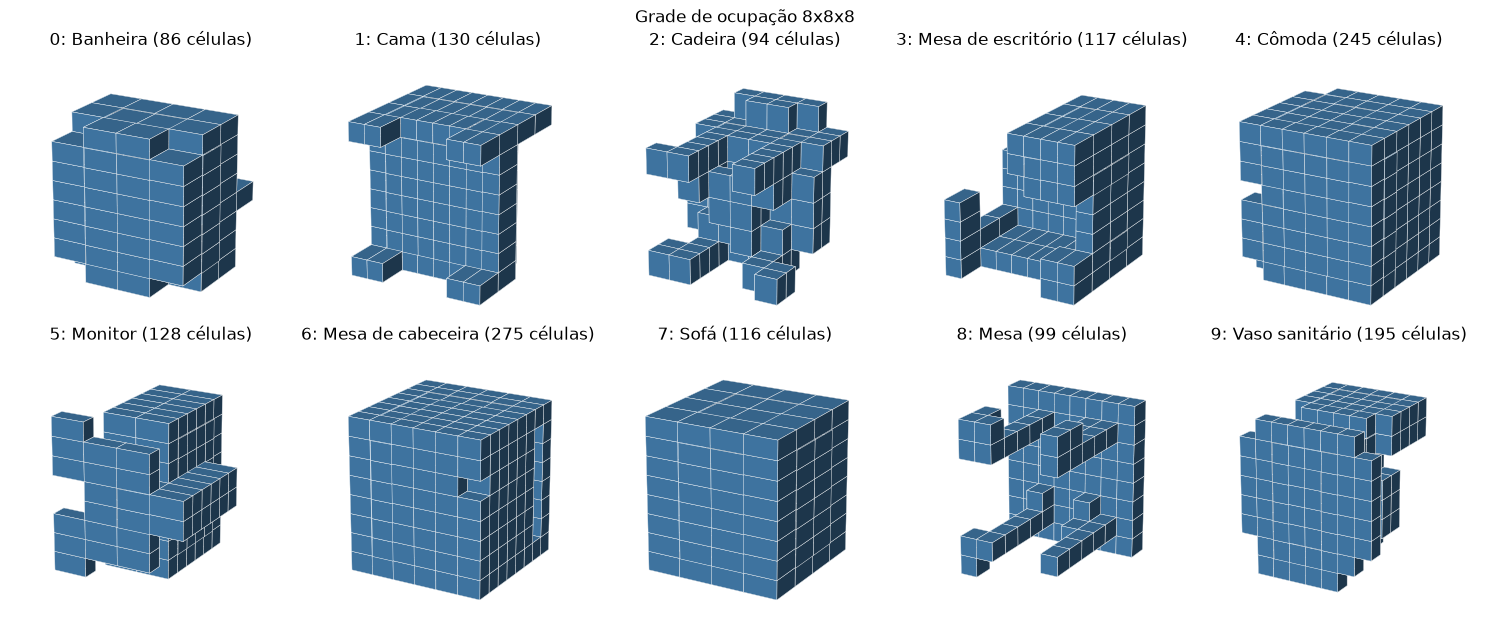

In [9]:
fig = plt.figure(figsize=(15, 6.5))
for c in range(10):
    # Primeiro objeto de treino da classe c, reorganizado como grade (x, y, z)
    i = np.where(y_train == c)[0][0]
    grid3d = X_train[i].reshape(GRID, GRID, GRID).astype(bool)

    ax = fig.add_subplot(2, 5, c + 1, projection='3d')
    ax.voxels(grid3d, facecolors='steelblue', edgecolor='white', linewidth=0.3)

    # Mesmo ângulo e escala dos gráficos da etapa 2
    ax.view_init(elev=20, azim=-60)
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(f'{c}: {CLASS_NAMES[c]} ({grid3d.sum()} células)'); ax.set_axis_off()

fig.suptitle('Grade de ocupação 8x8x8')
plt.tight_layout(); plt.show()